# X1 — variante: alvo binário (todas as vértebras), orçamento por frames rotulados/vídeo

Combina as duas variações já existentes do [X1 frames/vídeo](experiment_1_does_ssl_helps_frames_per_video.ipynb):

- **Orçamento por frames/vídeo**, como em
  [X1 frames/vídeo, todas as vértebras](experiment_1_does_ssl_helps_frames_per_video_multiclass_all.ipynb)
  (`FRAMES_PER_VIDEO = [1, 2, 3, 5]`, agrupado por `video_id`, não por paciente).
- **Alvo binário**, como em [X1-binário](experiment_1_does_ssl_helps_binary.ipynb), mas fundindo
  **todas** as vértebras anotadas (C2..C8) numa única classe de primeiro plano — não só C2+C4 —
  via `target_variant="binary_all"` (`n_classes=2`). Ver `configs/experiment/x1-binario-all/`, que
  espelha `configs/experiment/x1-binario/` trocando `target_variant` de `binary_c2_c4` para
  `binary_all`.

`binary_all` foi derivado de `multiclass_all` com `scripts/build_binary_mask_variant.py`
(`isin(multiclass_all, [1..7])` — toda vértebra vira `1`, fundo continua `0`), verificado pixel a
pixel contra os 971 frames anotados antes de treinar qualquer coisa.

Os resultados são gravados à parte, em `logs/x1-frames-per-video-binario-all/` — não são
comparáveis linha a linha com `logs/x1-frames-per-video-multiclass-all/` (o alvo mudou de 8 classes
para 2) nem com `logs/x1-binario/` (o orçamento mudou de "% de pacientes" para "frames/vídeo"), mas
a leitura segue a mesma lógica: margem de anotação, ganho do não anotado, recuperação de margem por
método.

**Por que isso existe, e não só `C2-C8 (macro)`** (a métrica-resumo do notebook multiclasse): aquela
métrica é a média de sete classes calculadas separadamente sobre o argmax de um modelo
*multiclasse* — sensível, por construção, a confusão entre vértebras vizinhas (ver a ressalva
daquele notebook). `FG` aqui não tem essa confusão para começar, porque nunca existiu uma segunda
estrutura para confundir com. Uma diferença `FG` vs. `C2-C8 (macro)` mistura dois efeitos (treinar
binário desde o início + ausência de confusão entre vértebras) — não isole um sem o outro.


In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import sys
import torchmetrics

In [3]:
import sys
sys.path.append("../../")

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.vfss_frame_dataset import (
    load_video_frame_dataframe,
    split_by_group,
    apply_label_regime_by_count,
    build_unlabeled_frame_pool,
)

## Parâmetros

`SEEDS` varia **apenas** a estocasticidade de treino (inicialização, ordem dos batches,
augmentation). `SPLIT_SEED` e `LABEL_SEED` ficam **fixos de propósito**:

- mexer em `SPLIT_SEED` trocaria o fold, e passaríamos a medir variância de split em vez do efeito
  do orçamento;
- mexer em `LABEL_SEED` quebraria o **aninhamento** dos regimes (todo frame revelado com 2
  frames/vídeo continua revelado com 3, 4 e 5), que é o que torna os quatro orçamentos diretamente
  comparáveis. Ver a docstring de `apply_label_regime_by_count`.

`LABEL_GROUP_COLUMN = "video_id"` aqui não é um detalhe: é o que faz o orçamento ser "N frames por
vídeo" em vez de "N frames por paciente" — um paciente pode ter mais de um vídeo, e cada vídeo
revela sua própria cota.

In [4]:
DATASET_PATH = "/data_ssd/caioseda/data/dataset_inca_all_frames/"

# --- o fold (fixo) ---
SPLIT_SEED = 42
SPLIT_RATIOS = (0.7, 0.10, 0.2)
SPLIT_GROUP_COLUMN = "paciente_id"

# --- regime de rotulos (so os frames ANOTADOS), por CONTAGEM DE FRAMES/VIDEO ---
LABEL_SEED = 42                 # FIXO: garante o aninhamento entre orcamentos
LABEL_GROUP_COLUMN = "video_id" # o orcamento e "N frames por video", nao por paciente
FRAMES_PER_VIDEO = [1, 2, 3, 5]

# --- pool nao rotulado REAL (frames que nunca foram anotados) ---
# Identico em todos os orcamentos: e o que permite medir o ganho do SSL tambem no regime maximo.
UNLABELED_POOL_SIZE = 8000
UNLABELED_POOL_FRAME_STRIDE = 3   # frames consecutivos de VFSS sao quase identicos
UNLABELED_POOL_SEED = 42
UNLABELED_POOL_SPLITS = ["train"] # nenhum frame de paciente de val/test entra no treino

# --- politica de amostragem dos nao rotulados (DEFAULT do X1) ---
# Cada slot nao rotulado vem do mesmo video de um dos rotulados do batch, em qualquer posicao.
# Alternativas ('global', 'temporal_window') sao comparadas no X1B, nao aqui.
UNLABELED_POLICY = "same_video"

# --- grade ---
SEEDS = [42]               # lista; comeca com um valor so
METHODS = ["supervised", "fixmatch", "meanteacher", "diffrect"]
# DiffRect custa ~5.4x um passo supervisionado (medido: 0.243 s/passo contra 0.045, RTX 6000
# Ada, batch 6 a 256x256), entao a grade com ele leva ~5x mais tempo. Antes de interpretar uma
# celula fraca do DiffRect, conferir se experiment_acdc_ssl_reproduction.ipynb passou: la o
# metodo tem gabarito publicado, aqui nao.

# --- treino ---
MAX_STEPS = 8000           # orcamento de compute FIXO: todo run ve o mesmo numero de imagens
VAL_EVERY_N_STEPS = 500    # convertido em `check_val_every_n_epoch` por orcamento
BATCH_SIZE = 8
LABELED_BATCH_SIZE = 4     # os outros 4 vem do fluxo nao rotulado, em TODOS os orcamentos

# --- avaliacao ---
# TODAS as vertebras anotadas (C2..C8) fundidas numa unica classe de primeiro plano, via
# target_variant='binary_all'. FG esta presente em 971/971 frames anotados (cada frame tem pelo
# menos uma vertebra rotulada) -- ao contrario do multiclasse por vertebra, aqui nao ha classe rara.
CLASS_IDS = {1: "FG"}
NUM_CLASSES = 2
METRICS = ["dice", "iou", "assd", "hd95"]

# Caminhos absolutos: o notebook roda a partir do proprio diretorio, e o Experiment resolveria
# `logs/` relativo a ele -- espalhando checkpoints dentro de notebooks/.
REPO_ROOT = Path("../../").resolve()
CONFIG_DIR = REPO_ROOT / "configs/experiment/x1-binario-all"   # target_variant='binary_all'; so o regime de rotulo muda
LOGS_DIR = REPO_ROOT / "logs"
# Diretorio PROPRIO: nao compartilhar com logs/x1-frames-per-video-multiclass-all (multiclasse),
# logs/x1-binario (so C2+C4) nem logs/x1-frames-per-video (so C2/C4) -- alvos e regimes diferentes.
RESULTS_DIR = LOGS_DIR / "x1-frames-per-video-binario-all"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = RESULTS_DIR / "results_per_sample.csv"


---

# Parte 1 — O fold

Reproduz aqui, em pandas, exatamente a divisão que o `VFSSFrameDatasetBase` faz internamente
(mesmas funções, mesmas sementes), para poder auditá-la antes de treinar qualquer coisa.

In [5]:
df = load_video_frame_dataframe(DATASET_PATH)
df = split_by_group(df, SPLIT_GROUP_COLUMN, seed=SPLIT_SEED, ratios=SPLIT_RATIOS)

split_summary = (
    df.groupby("split")
      .agg(frames=("video_frame", "size"),
           pacientes=("paciente_id", "nunique"),
           videos=("video_id", "nunique"))
      .reindex(["train", "val", "test"])
)
split_summary["% frames"] = (100 * split_summary.frames / len(df)).round(1)
print(f"Fold unico: split_seed={SPLIT_SEED}, agrupado por {SPLIT_GROUP_COLUMN}, ratios={SPLIT_RATIOS}")
split_summary

Fold unico: split_seed=42, agrupado por paciente_id, ratios=(0.7, 0.1, 0.2)


,frames,pacientes,videos,% frames
split,,,,
train,690,69,165,71.8
val,99,25,25,10.3
test,172,20,42,17.9


### Regimes de rótulo

Nenhuma linha é descartada: o que muda entre os orçamentos é só a coluna `is_labeled`. O total de
frames de treino é idêntico nos quatro — o que muda é **quantos frames de cada vídeo** carregam
supervisão (até `FRAMES_PER_VIDEO`, ou todos os que o vídeo tiver, se tiver menos).

In [6]:
regime_rows = []
labeled_videos_by_count = {}
labeled_frame_keys_by_count = {}   # (video_id, frame_id) revelados -- usado na auditoria de aninhamento

for n_frames in FRAMES_PER_VIDEO:
    regime_df = apply_label_regime_by_count(
        df,
        group_column=LABEL_GROUP_COLUMN,
        frames_per_group=n_frames,
        seed=LABEL_SEED,
        label_regime_splits=("train",),
    )
    train_df = regime_df[regime_df.split == "train"]
    labeled = train_df[train_df.is_labeled]
    labeled_videos_by_count[n_frames] = set(labeled.video_id)
    labeled_frame_keys_by_count[n_frames] = set(zip(labeled.video_id, labeled.frame_id))

    frames_por_video_treino = train_df.groupby("video_id").size()
    videos_curtos = int((frames_por_video_treino < n_frames).sum())

    regime_rows.append({
        "frames/vídeo": n_frames,
        "anotados (treino)": len(train_df),
        "rótulos revelados": len(labeled),
        "% revelado (do treino anotado)": round(100 * len(labeled) / len(train_df), 1),
        "rótulos escondidos": len(train_df) - len(labeled),
        "vídeos revelados": labeled.video_id.nunique(),
        "pacientes revelados": labeled.paciente_id.nunique(),
        "vídeos com menos de N frames anotados": videos_curtos,
    })

regime_summary = pd.DataFrame(regime_rows).set_index("frames/vídeo")
regime_summary

,anotados (treino),rótulos revelados,% revelado (do treino anotado),rótulos escondidos,vídeos revelados,pacientes revelados,vídeos com menos de N frames anotados
frames/vídeo,,,,,,,
1,690,165,23.9,525,165,69,0
2,690,330,47.8,360,165,69,0
3,690,494,71.6,196,165,69,1
5,690,690,100.0,0,165,69,123


### Frames rotulados totais por regime

Quantidade total de frames que ficam com o rótulo revelado no treino, em cada um dos quatro
regimes -- a mesma coluna `rótulos revelados` da tabela acima, isolada aqui para referência
rápida (é também o número que entra no denominador de `LABELED_BATCH_SIZE` por passo).

In [7]:
total_labeled_frames = regime_summary[["rótulos revelados", "vídeos revelados", "pacientes revelados"]].copy()
total_labeled_frames.index.name = "frames revelados por vídeo (orçamento)"

print("Frames rotulados (revelados) totais por regime, no split de treino:")
total_labeled_frames

Frames rotulados (revelados) totais por regime, no split de treino:


,rótulos revelados,vídeos revelados,pacientes revelados
frames revelados por vídeo (orçamento),,,
1,165,165,69
2,330,165,69
3,494,165,69
5,690,165,69


### % de dados rotulados totais

Duas leituras da mesma contagem, com denominadores diferentes:

- **% do treino anotado**: quanto do total de frames anotados de treino (o universo sobre o qual o
  regime atua) fica com o rótulo revelado -- mesma coluna `% revelado` da Parte 1.
- **% de todo o dataset anotado**: quanto isso representa sobre a base anotada inteira
  (treino+val+teste), já que val/teste ficam sempre 100% revelados e não fazem parte do orçamento.

In [8]:
total_annotated_all_splits = len(df)
total_annotated_train = int((df.split == "train").sum())

pct_rows = []
for n_frames in FRAMES_PER_VIDEO:
    revelados = int(regime_summary.loc[n_frames, "rótulos revelados"])
    pct_rows.append({
        "frames/vídeo": n_frames,
        "rótulos revelados": revelados,
        "% do treino anotado": round(100 * revelados / total_annotated_train, 1),
        "% de todo o dataset anotado (treino+val+teste)": round(100 * revelados / total_annotated_all_splits, 1),
    })

pct_labeled_summary = pd.DataFrame(pct_rows).set_index("frames/vídeo")
print(f"Total de frames anotados no dataset: {total_annotated_all_splits} "
      f"({total_annotated_train} no treino, onde o regime se aplica).")
pct_labeled_summary

Total de frames anotados no dataset: 961 (690 no treino, onde o regime se aplica).


,rótulos revelados,% do treino anotado,% de todo o dataset anotado (treino+val+teste)
frames/vídeo,,,
1,165,23.9,17.2
2,330,47.8,34.3
3,494,71.6,51.4
5,690,100.0,71.8


### O pool não rotulado

O que a literatura de SSL não tem: frames que **nunca foram anotados**. São a maior parte do
dataset, e entram no treino em todos os orçamentos.

O pool é construído só a partir de vídeos do split de **treino** — um frame não rotulado de um
paciente de teste seria vazamento tão real quanto um rótulo.

In [9]:
pool_df = build_unlabeled_frame_pool(
    DATASET_PATH,
    df,
    splits=UNLABELED_POOL_SPLITS,
    pool_size=UNLABELED_POOL_SIZE,
    frame_stride=UNLABELED_POOL_FRAME_STRIDE,
    seed=UNLABELED_POOL_SEED,
)

# Quantos frames existiriam sem stride nem teto, para dimensionar o quanto estamos deixando na mesa.
pool_maximo = build_unlabeled_frame_pool(DATASET_PATH, df, splits=UNLABELED_POOL_SPLITS)

train_anotados = int((df.split == "train").sum()) if "split" in df else None
print(f"Frames anotados no dataset inteiro : {len(df)}")
print(f"Frames nao anotados elegiveis      : {len(pool_maximo)}  (videos de {UNLABELED_POOL_SPLITS})")
print(f"Pool efetivamente usado            : {len(pool_df)}  "
      f"(stride={UNLABELED_POOL_FRAME_STRIDE}, teto={UNLABELED_POOL_SIZE}, seed={UNLABELED_POOL_SEED})")
print(f"Videos representados no pool       : {pool_df.video_id.nunique()}")
print(f"Pacientes representados no pool    : {pool_df.paciente_id.nunique()}")
print(f"\nRazao nao rotulado : rotulado no batch = "
      f"{BATCH_SIZE - LABELED_BATCH_SIZE}:{LABELED_BATCH_SIZE} (fixa em todos os orcamentos)")
print(f"Cada frame do pool e visto ~{MAX_STEPS * (BATCH_SIZE - LABELED_BATCH_SIZE) / len(pool_df):.1f}x "
      f"ao longo dos {MAX_STEPS} passos.")

Frames anotados no dataset inteiro : 961
Frames nao anotados elegiveis      : 31953  (videos de ['train'])
Pool efetivamente usado            : 8000  (stride=3, teto=8000, seed=42)
Videos representados no pool       : 165
Pacientes representados no pool    : 69

Razao nao rotulado : rotulado no batch = 4:4 (fixa em todos os orcamentos)
Cada frame do pool e visto ~4.0x ao longo dos 8000 passos.


### Auditoria do desenho

Três invariantes que precisam valer para o experimento significar o que se propõe. Se qualquer um
falhar, a comparação entre orçamentos está contaminada.

In [10]:
# 1. Aninhamento: todo frame revelado num orcamento menor continua revelado no maior.
for smaller, larger in zip(FRAMES_PER_VIDEO, FRAMES_PER_VIDEO[1:]):
    assert labeled_frame_keys_by_count[smaller] <= labeled_frame_keys_by_count[larger], (
        f"Aninhamento quebrado entre {smaller} e {larger} frames/video -- LABEL_SEED variou?"
    )

# 2. Numero de imagens vistas constante: os quatro orcamentos tem o mesmo total de frames anotados
#    de treino (o que muda e quantos deles carregam rotulo) e o mesmo pool nao rotulado.
assert regime_summary["anotados (treino)"].nunique() == 1, "O total de frames anotados mudou entre orcamentos."

# 3. Test set intocado pelo regime: o mascaramento so se aplica ao split de treino.
for n_frames in FRAMES_PER_VIDEO:
    regime_df = apply_label_regime_by_count(df, group_column=LABEL_GROUP_COLUMN, frames_per_group=n_frames,
                                             seed=LABEL_SEED, label_regime_splits=("train",))
    assert regime_df[regime_df.split == "test"].is_labeled.all(), "Test set foi afetado pelo regime."

# 4. O pool nao vaza: nenhum frame nao rotulado vem de paciente de val/test, e nenhum frame
#    anotado aparece duas vezes (uma como anotado, outra como "nao rotulado").
pacientes_treino = set(df[df.split == "train"].paciente_id)
assert set(pool_df.paciente_id) <= pacientes_treino, "O pool contem pacientes fora do split de treino."
assert not (set(zip(pool_df.video_id, pool_df.frame_id)) & set(zip(df.video_id, df.frame_id))), (
    "Um frame anotado apareceu tambem no pool nao rotulado."
)

# 5. Ha fluxo nao supervisionado em TODOS os orcamentos -- inclusive no maior. E o que distingue este
#    desenho do da literatura, e o que faz a celula do regime de 5 frames/video medir alguma coisa.
assert len(pool_df) > 0, "Sem pool, o orcamento maximo nao tem dados nao rotulados e o SSL degenera."

print("OK - aninhamento, imagens vistas constantes, test set intocado, pool sem vazamento.")
print(f"    videos revelados por regime: { {n: len(v) for n, v in labeled_videos_by_count.items()} }")
print(f"    pool nao rotulado (todos os regimes): {len(pool_df)} frames")

OK - aninhamento, imagens vistas constantes, test set intocado, pool sem vazamento.
    videos revelados por regime: {1: 165, 2: 165, 3: 165, 5: 165}
    pool nao rotulado (todos os regimes): 8000 frames


### O que a política `same_video` implica sob o regime por contagem de frames

No X1 original, orçamentos baixos revelavam poucos *pacientes* inteiros — logo poucos vídeos
tinham qualquer rótulo, e sob `same_video` isso restringia bastante o fluxo não rotulado
alcançável (ver o notebook original). Aqui o regime revela frames dentro de **todo vídeo do
treino** (até `FRAMES_PER_VIDEO`, ou todos os que tiver), então, ao contrário do X1 original, todo
vídeo de treino tem pelo menos um frame revelado em qualquer um dos quatro regimes -- desde que
tenha pelo menos um frame anotado, o que é garantido por construção. Sob `same_video`, isso
significa que a cobertura do pool não rotulado alcançável deveria ser (por desenho) a mesma nos
quatro regimes. A tabela abaixo existe para **confirmar** essa expectativa, não para medir uma
diferença como no X1 original.

In [11]:
cobertura_rows = []
for n_frames in FRAMES_PER_VIDEO:
    regime_df = apply_label_regime_by_count(df, group_column=LABEL_GROUP_COLUMN, frames_per_group=n_frames,
                                             seed=LABEL_SEED, label_regime_splits=("train",))
    revelados = regime_df[(regime_df.split == "train") & regime_df.is_labeled]
    videos_revelados = set(revelados.video_id)

    # `same_video`: so vídeos com rotulo revelado podem contribuir frames nao rotulados.
    alcancavel = pool_df[pool_df.video_id.isin(videos_revelados)]
    cobertura_rows.append({
        "frames/vídeo": n_frames,
        "vídeos com rótulo": len(videos_revelados),
        "pacientes com rótulo": revelados.paciente_id.nunique(),
        "pool alcançável (same_video)": len(alcancavel),
        "% do pool alcançável": round(100 * len(alcancavel) / len(pool_df), 1),
        "pool alcançável (global)": len(pool_df),
    })

cobertura = pd.DataFrame(cobertura_rows).set_index("frames/vídeo")
display(cobertura)
total_videos_treino = df[df.split == "train"].video_id.nunique()
print(f"Vídeos de treino no total: {total_videos_treino}.")
print("Se 'vídeos com rótulo' bater com esse total nas quatro linhas, a cobertura do same_video")
print("não varia com o regime -- diferente do X1 original, onde ela crescia com o orçamento.")

,vídeos com rótulo,pacientes com rótulo,pool alcançável (same_video),% do pool alcançável,pool alcançável (global)
frames/vídeo,,,,,
1,165,69,8000,100.0,8000
2,165,69,8000,100.0,8000
3,165,69,8000,100.0,8000
5,165,69,8000,100.0,8000


Vídeos de treino no total: 165.
Se 'vídeos com rótulo' bater com esse total nas quatro linhas, a cobertura do same_video
não varia com o regime -- diferente do X1 original, onde ela crescia com o orçamento.


> ⚠️ **Ressalvas a carregar para a leitura dos resultados.**
>
> 1. **Vídeos curtos convergem entre regimes.** Um vídeo com N frames anotados revela exatamente os
>    mesmos frames em todo regime `FRAMES_PER_VIDEO >= N` (a Parte 1 lista quantos vídeos caem
>    nesse caso, por regime). Isso é intencional — não há de onde tomar mais frames rotulados
>    nesses vídeos, e a alternativa seria descartá-los — mas significa que o regime de 5
>    frames/vídeo pode, na prática, coincidir com o de 4 ou 3 para uma fração do treino, o que
>    atenua a diferença observada entre orçamentos altos. Com `SEEDS = [42]` ainda não há barra de
>    erro nenhuma: uma única semente não sustenta um veredito.
> 2. **Deriva de distribuição do pool.** Os frames anotados foram escolhidos por alguém,
>    provavelmente em fases específicas da deglutição. O pool inclui frames em que as vértebras
>    estão ocultas ou o contraste ainda não chegou — exatamente a condição em que pseudo-rótulos
>    degradam. Antes de culpar o método, olhe `train/pseudo_*` e `train/teacher_*` no
>    TensorBoard: são medidos contra a ground truth que o regime escondeu.
> 3. **Cobertura do `same_video` deixa de ser o efeito medido** (ver a célula acima): ao contrário
>    do X1 original, aqui todo vídeo de treino contribui dado não rotulado em qualquer regime, então
>    a curva desta variante isola melhor "quantos rótulos por vídeo" de "quantos vídeos têm
>    rótulo" — as duas coisas que o X1 original misturava.
> 4. **`FG` está presente em praticamente todo frame** (971/971 frames anotados têm pelo menos uma
>    vértebra rotulada — ver a introdução). Isso tem duas consequências boas para esta variante,
>    ao contrário do notebook multiclasse por vértebra:
>    - o artefato de `nanmean` que descarta frames com estrutura ausente **dos dois lados**
>      (Dice/IoU) praticamente não ocorre aqui, já que `FG` quase nunca está ausente da ground
>      truth;
>    - ASSD/HD95 já não usam `NaN` para "estrutura não detectada numa predição" desde a correção em
>      `src/metrics.py` (penalizam com a diagonal da imagem, um pior caso definido, em vez de
>      descartar o frame do `nanmean`) — então mesmo um modelo que erre a detecção de `FG` num
>      frame entra na média como o pior caso, não desaparece dela.
>    Em suma: a comparação entre orçamentos aqui é mais confiável que nas colunas por vértebra do
>    notebook multiclasse, onde C6/C7/C8 têm poucas amostras e ainda estão sujeitas ao caso
>    "ausente dos dois lados".


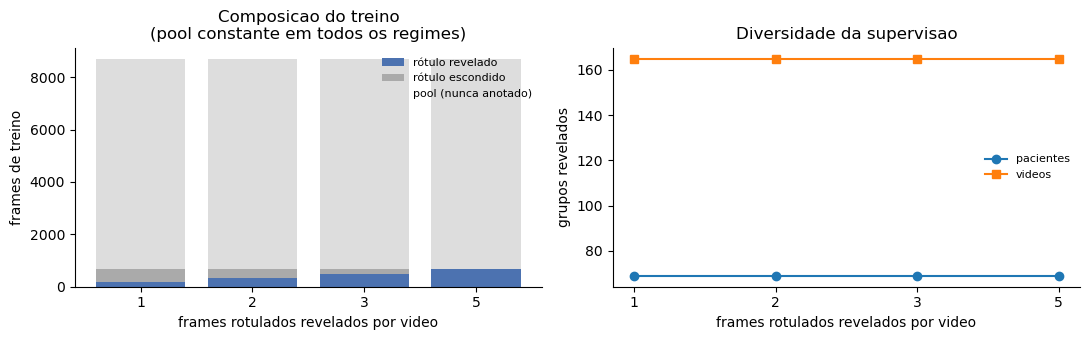

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))

x = np.arange(len(FRAMES_PER_VIDEO))
labels = [str(n) for n in FRAMES_PER_VIDEO]

axes[0].bar(x, regime_summary["rótulos revelados"], label="rótulo revelado", color="#4C72B0")
axes[0].bar(x, regime_summary["rótulos escondidos"], bottom=regime_summary["rótulos revelados"],
            label="rótulo escondido", color="#AAAAAA")
axes[0].bar(x, [len(pool_df)] * len(x),
            bottom=regime_summary["anotados (treino)"],
            label="pool (nunca anotado)", color="#DDDDDD")
axes[0].set_xticks(x); axes[0].set_xticklabels(labels)
axes[0].set_ylabel("frames de treino")
axes[0].set_title("Composicao do treino\n(pool constante em todos os regimes)")
axes[0].legend(frameon=False, fontsize=8)

axes[1].plot(x, regime_summary["pacientes revelados"], "o-", label="pacientes")
axes[1].plot(x, regime_summary["vídeos revelados"], "s-", label="videos")
axes[1].set_xticks(x); axes[1].set_xticklabels(labels)
axes[1].set_ylabel("grupos revelados")
axes[1].set_title("Diversidade da supervisao")
axes[1].legend(frameon=False, fontsize=8)

for ax in axes:
    ax.set_xlabel("frames rotulados revelados por video")
    ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()

---

# Parte 2 — Treino e avaliação

A grade é `semente × método × orçamento`, onde orçamento agora é `FRAMES_PER_VIDEO`. Três escolhas
de desenho que valem explicitar (idênticas ao X1 original):

**Orçamento de compute fixo em passos, não em épocas.** Com o `TwoStreamBatchSampler`, uma "época"
é `len(rotulados) // labeled_batch_size` e encolhe conforme o orçamento de anotação. Fixar
`max_steps` garante que todo run vê o mesmo número de imagens — e é também o que ancora o
cronograma de consistência (`consistency_*_fraction`, ver `src/models/ssl/base.py`).

**Composição de batch idêntica em todos os orçamentos.** Todo batch tem
`LABELED_BATCH_SIZE` linhas rotuladas e `BATCH_SIZE - LABELED_BATCH_SIZE` não rotuladas, inclusive
no regime de 5 frames/vídeo. Sem o pool, o regime mais generoso cairia num DataLoader comum com 8
linhas rotuladas por passo — o dobro de gradiente supervisionado dos demais — e a margem medida
sairia inflada por construção.

**Nenhuma célula é degenerada.** Como o fluxo não rotulado é real e independe de
`label_frames_per_group`, FixMatch e Mean Teacher têm um termo de consistência ativo em todo
regime, inclusive no de 5 frames/vídeo — a célula `(método SSL, 5 frames/vídeo)` é justamente o
resultado que interessa reportar: o que os frames não anotados somam sobre a maior quantidade de
anotação testada aqui.

In [13]:
import torch
from omegaconf import OmegaConf

from src.experiment import Experiment
from src.evaluation import evaluate_per_class, aggregate_per_class

METHOD_CONFIG = {method: CONFIG_DIR / f"x1-binario-all-unet-{method}.yaml" for method in
                 ["supervised", "fixmatch", "meanteacher", "diffrect"]}

def run_id(method: str, frames_per_video: int, seed: int) -> str:
    return f"{method}-fpv{frames_per_video:02d}-s{seed}"


/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


In [14]:
def steps_per_epoch(frames_per_video: int) -> int:
    """Batches por epoca sob o regime dado -- define de quantas em quantas epocas validar.

    Com o pool nao rotulado ativo, o TwoStreamBatchSampler e usado em TODOS os orcamentos (inclusive
    no maior), entao uma epoca e sempre uma passada pelos rotulos revelados.
    """
    n_labeled = int(regime_summary.loc[frames_per_video, "rótulos revelados"])
    return max(1, n_labeled // LABELED_BATCH_SIZE)


def build_overrides(method: str, frames_per_video: int, seed: int) -> dict:
    """Sobrescritas aplicadas por cima do YAML do metodo (OmegaConf.merge, aninhado)."""
    check_val_every_n_epoch = max(1, round(VAL_EVERY_N_STEPS / steps_per_epoch(frames_per_video)))
    return {
        # Prefixo "x1-frames-bin-all-", igual ao `run_name_prefix` de
        # configs/sweep/x1-frames-per-video-binario-all.yaml -- mesma celula, mesmo nome de run,
        # rodada pelo notebook ou pelo sweep.
        "name": f"x1-frames-bin-all-{run_id(method, frames_per_video, seed)}",
        "trainer": {"params": {
            "max_steps": MAX_STEPS,
            "check_val_every_n_epoch": check_val_every_n_epoch,
        }},
        "lr_scheduler": {"params": {"T_max": MAX_STEPS}},
        "data": {"params": {
            "batch_size": BATCH_SIZE,
            "shared_dataset_params": {
                # Substitui `label_fraction` do YAML: revela ate N frames por video, nao uma fracao
                # de grupos inteiros. Ver `apply_label_regime_by_count`.
                "label_frames_per_group": frames_per_video,
                "label_seed": LABEL_SEED,
                "label_group_column": LABEL_GROUP_COLUMN,
                "split_seed": SPLIT_SEED,
                "split_group_column": SPLIT_GROUP_COLUMN,
                # Pool identico em todos os orcamentos: e a variavel que NAO varia.
                "unlabeled_pool_size": UNLABELED_POOL_SIZE,
                "unlabeled_pool_frame_stride": UNLABELED_POOL_FRAME_STRIDE,
                "unlabeled_pool_seed": UNLABELED_POOL_SEED,
                "unlabeled_pool_splits": UNLABELED_POOL_SPLITS,
                "expose_hidden_targets": True,   # diagnostico de pseudo-rotulo; nenhuma loss le
            },
            "train_batch_sampler": {"params": {
                "batch_size": BATCH_SIZE,
                "labeled_batch_size": LABELED_BATCH_SIZE,
                "seed": seed,
                "unlabeled_policy": UNLABELED_POLICY,   # variado apenas no X1B
            }},
        }},
    }

pd.DataFrame([
    {"frames/vídeo": n, "passos/época": steps_per_epoch(n),
     "épocas até MAX_STEPS": MAX_STEPS // steps_per_epoch(n),
     "valida a cada N épocas": max(1, round(VAL_EVERY_N_STEPS / steps_per_epoch(n)))}
    for n in FRAMES_PER_VIDEO
]).set_index("frames/vídeo")


,passos/época,épocas até MAX_STEPS,valida a cada N épocas
frames/vídeo,,,
1,41,195,12
2,82,97,6
3,123,65,4
5,172,46,3


### O runner

O treino **não roda mais neste kernel**. `submit_sweep` lança a grade numa sessão tmux destacada e
devolve na hora; `watch_sweep` só observa o estado em disco. Fechar o notebook, reiniciar o kernel
ou perder o SSH não mata o treino — que era a razão inteira da mudança.

A grade em si vive em [`configs/sweep/x1-frames-per-video-binario-all.yaml`](../../configs/sweep/x1-frames-per-video-binario-all.yaml) (os valores) e
em `src/sweeps/` (a lógica que depende do regime, como converter `val_every_n_steps` em
`check_val_every_n_epoch`). `tests/test_sweeps.py` afirma que a configuração que o sweep gera hoje é
a mesma que produziu as linhas já gravadas em `logs/x1-frames-per-video-binario-all/results_per_sample.csv` — então relançar não retreina nada nem torna
os resultados novos incomparáveis com os antigos.

Retomada em dois níveis: células concluídas são puladas, e uma célula interrompida no meio volta de
`checkpoints/last.ckpt` com o cronograma (LR, peso de consistência, EMA) exatamente onde estava.


In [15]:
def load_results() -> pd.DataFrame:
    if RESULTS_CSV.exists():
        return pd.read_csv(RESULTS_CSV)
    return pd.DataFrame()


def save_results(results: pd.DataFrame) -> None:
    results.to_csv(RESULTS_CSV, index=False)


def train_and_evaluate(method: str, frames_per_video: int, seed: int) -> pd.DataFrame:
    """Treina uma celula da grade e devolve as metricas por amostra do test set."""
    experiment = Experiment(
        config_path=str(METHOD_CONFIG[method]),
        overrides=build_overrides(method, frames_per_video, seed),
        log_dir=LOGS_DIR,
    )
    experiment.run(seed=seed)

    # O Mean Teacher reporta pelo teacher (os pesos EMA sao o modelo melhor); os demais pelo proprio
    # modelo. `_eval_forward` existe so no wrapper do Mean Teacher.
    forward_fn = getattr(experiment.lit_module, "_eval_forward", None)

    per_sample = evaluate_per_class(
        experiment.lit_module,
        experiment.data_module.test_dataloader(),
        num_classes=NUM_CLASSES,
        class_ids=CLASS_IDS,
        forward_fn=forward_fn,
    )
    per_sample["output_dir"] = str(experiment.experiment_run_dir)
    return per_sample

In [16]:
from src.sweep import submit_sweep, watch_sweep, sweep_status

SWEEP_CONFIG = "configs/sweep/x1-frames-per-video-binario-all.yaml"

# O que está pronto, o que falta, o que pode ser retomado -- lido do disco, sem depender de o
# processo estar vivo.
sweep_status(SWEEP_CONFIG)


,run_id,seed,frames_per_video,method,status
0,supervised-fpv01-s42,42,1,supervised,done (na CSV)
1,fixmatch-fpv01-s42,42,1,fixmatch,done (na CSV)
2,meanteacher-fpv01-s42,42,1,meanteacher,done (na CSV)
3,diffrect-fpv01-s42,42,1,diffrect,done (na CSV)
4,supervised-fpv02-s42,42,2,supervised,done (na CSV)
5,fixmatch-fpv02-s42,42,2,fixmatch,done (na CSV)
6,meanteacher-fpv02-s42,42,2,meanteacher,done (na CSV)
7,diffrect-fpv02-s42,42,2,diffrect,done (na CSV)
8,supervised-fpv03-s42,42,3,supervised,done (na CSV)
9,fixmatch-fpv03-s42,42,3,fixmatch,done (na CSV)


In [18]:
# Lança a grade destacada e devolve na hora. Seguro reexecutar: se a sessão ja existe, avisa em vez
# de duplicar o treino.
# submit_sweep(SWEEP_CONFIG)

# Acompanha. Interromper esta célula para de OLHAR, não para de treinar.
watch_sweep(SWEEP_CONFIG)


x1-frames-per-video-binario-all: 16/16 celulas concluidas (12:05:47)
               run_id  seed  frames_per_video      method        status
 supervised-fpv01-s42    42                 1  supervised done (na CSV)
   fixmatch-fpv01-s42    42                 1    fixmatch done (na CSV)
meanteacher-fpv01-s42    42                 1 meanteacher done (na CSV)
   diffrect-fpv01-s42    42                 1    diffrect done (na CSV)
 supervised-fpv02-s42    42                 2  supervised done (na CSV)
   fixmatch-fpv02-s42    42                 2    fixmatch done (na CSV)
meanteacher-fpv02-s42    42                 2 meanteacher done (na CSV)
   diffrect-fpv02-s42    42                 2    diffrect done (na CSV)
 supervised-fpv03-s42    42                 3  supervised done (na CSV)
   fixmatch-fpv03-s42    42                 3    fixmatch done (na CSV)
meanteacher-fpv03-s42    42                 3 meanteacher done (na CSV)
   diffrect-fpv03-s42    42                 3    diffrect done (na 

---

# Parte 3 — Leitura dos resultados

Duas perguntas distintas saem da mesma grade:

1. **Quanto vale anotar mais frames por vídeo?** A inclinação da curva do supervisionado entre 2 e
   5 frames/vídeo. Plana ⇒ anotar mais frames por vídeo não compra desempenho neste dataset.
2. **Quanto valem os frames não anotados?** A distância vertical entre a curva de cada método SSL e
   a do supervisionado, *no mesmo orçamento*. A leitura mais importante é no regime de **5
   frames/vídeo** (o maior testado aqui): ali o supervisionado já viu o máximo de anotação por
   vídeo deste desenho, e o que o método SSL adicionar vem majoritariamente dos frames nunca
   anotados.

### Uma única classe reportada: `FG`

Como o modelo já é treinado com `n_classes=2`, não há vértebras separadas aqui para fundir — a
tabela e os gráficos abaixo têm uma única coluna/classe, `FG`.

A comparação com o X1-multiclasse (todas as vértebras) é `FG` (aqui) vs. `C2-C8 (macro)`
([experiment_1_does_ssl_helps_frames_per_video_multiclass_all.ipynb](experiment_1_does_ssl_helps_frames_per_video_multiclass_all.ipynb))
— mas leia com a ressalva da introdução: a macro é sensível a confusão entre vértebras vizinhas e
`FG` não tem como sofrer dessa confusão (só existe uma estrutura aqui). Uma diferença entre as duas
mistura o efeito de treinar binário desde o início com o efeito de nunca ter havido confusão entre
vértebras — não isole um sem o outro.


In [19]:
results = load_results()

aggregated = aggregate_per_class(results, group_columns=["method", "frames_per_video", "seed"])
# Media entre sementes (com uma so semente, e a propria).
across_seeds = (
    aggregated
    .groupby(["method", "frames_per_video", "class"], as_index=False)[METRICS]
    .mean()
)

table = across_seeds.pivot_table(index=["frames_per_video", "method"], columns="class", values=METRICS)
table = table.reorder_levels([1, 0], axis=1).sort_index(axis=1, level=0)
table.round(4)


class                             FG                         
                                assd    dice     hd95     iou
frames_per_video method                                      
1                diffrect     1.5988  0.8308   6.1687  0.7203
                 fixmatch     1.7936  0.8683  10.7325  0.7751
                 meanteacher  1.2887  0.8714   6.0656  0.7797
                 supervised   1.3147  0.8816   5.4378  0.7957
2                diffrect     1.6501  0.8282   6.3923  0.7137
                 fixmatch     1.2644  0.8864   5.7804  0.8039
                 meanteacher  1.0515  0.8956   4.7009  0.8172
                 supervised   1.1994  0.8852   5.2471  0.8033
3                diffrect     1.4378  0.8478   5.5723  0.7431
                 fixmatch     1.2088  0.8857   5.5919  0.8021
                 meanteacher  1.3347  0.8845   6.3456  0.8007
                 supervised   1.2565  0.8890   6.2852  0.8076
5                diffrect     1.4229  0.8546   5.4556  0.7516
                 fixmatch     1.1915  0.8839   5.3884  0.7985
                 meanteacher  1.2038  0.8887   5.2421  0.8091
                 supervised   1.2146  0.8867   5.3684  0.8075

In [21]:
RESULTS_CSV

PosixPath('/data_ssd/caioseda/projetos/vfss-seg-benchmark/logs/x1-frames-per-video-binario-all/results_per_sample.csv')

### As curvas

A linha preta é o supervisionado: sua inclinação responde a pergunta 1. A distância das outras
linhas até ela, em cada x, responde a pergunta 2.

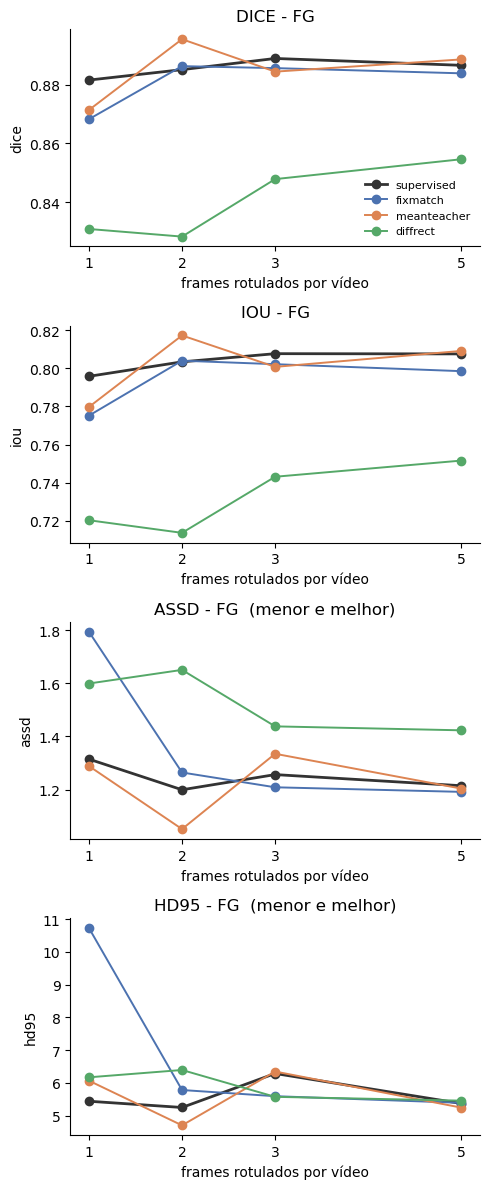

In [22]:
class_names = list(CLASS_IDS.values())
fig, axes = plt.subplots(len(METRICS), len(class_names), figsize=(5 * len(class_names), 3.0 * len(METRICS)), squeeze=False)
colors = {"supervised": "#333333", "fixmatch": "#4C72B0", "meanteacher": "#DD8452", "diffrect": "#55A868"}

for row, metric in enumerate(METRICS):
    for col, class_name in enumerate(class_names):
        ax = axes[row][col]
        subset = across_seeds[across_seeds["class"] == class_name]
        for method in METHODS:
            data = subset[subset.method == method].sort_values("frames_per_video")
            if data.empty:
                continue
            ax.plot(data.frames_per_video, data[metric], "o-",
                    label=method, color=colors.get(method), linewidth=2 if method == "supervised" else 1.4)
        ax.set_xticks(FRAMES_PER_VIDEO)
        ax.set_xlabel("frames rotulados por vídeo")
        ax.set_ylabel(metric)
        ax.set_title(f"{metric.upper()} - {class_name}" + ("  (menor e melhor)" if metric in ("assd", "hd95") else ""))
        ax.spines[["top", "right"]].set_visible(False)
        if row == 0 and col == 0:
            ax.legend(frameon=False, fontsize=8)

plt.tight_layout()


### Grade método × orçamento (barras)

Linha = orçamento (5 frames/vídeo no topo, 1 na base), coluna = métrica; cada célula é um gráfico
de barras comparando os métodos naquele orçamento/métrica, para a única classe reportada (`FG`).


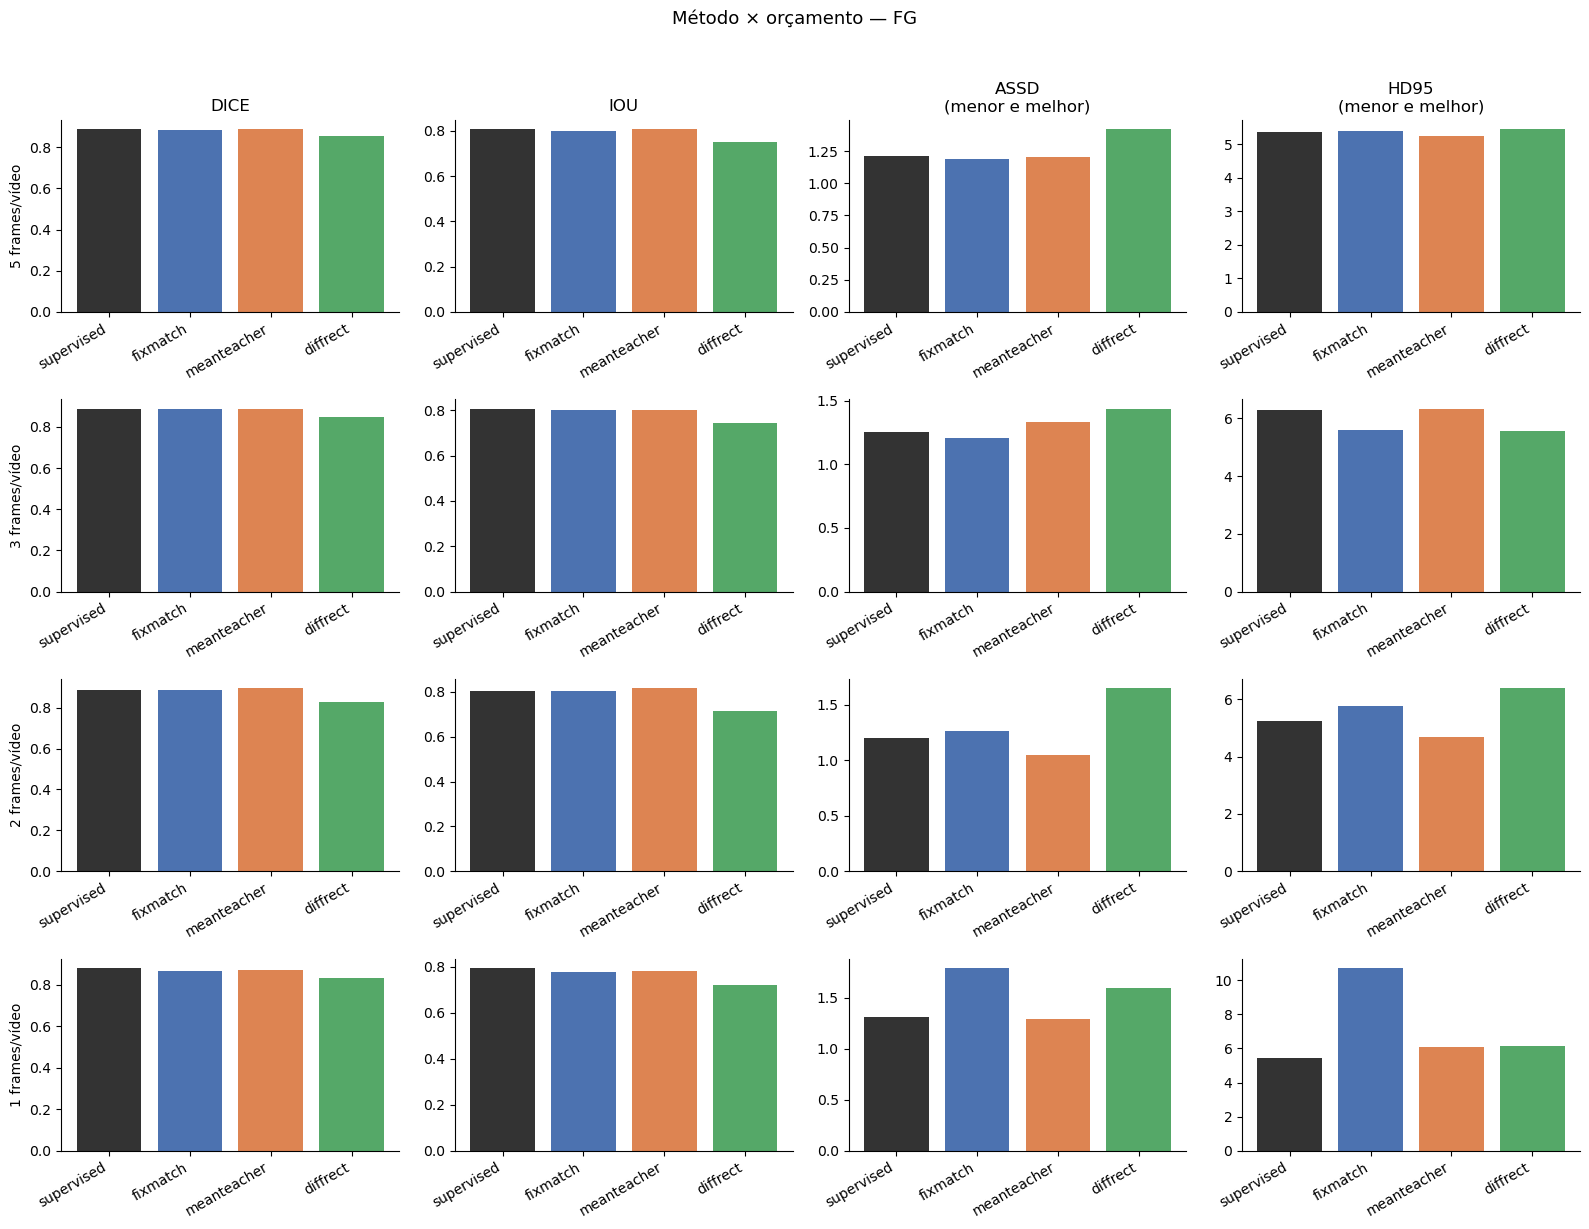

In [24]:
method_colors = {"supervised": "#333333", "fixmatch": "#4C72B0", "meanteacher": "#DD8452", "diffrect": "#55A868"}
frames_desc = sorted(FRAMES_PER_VIDEO, reverse=True)


def bar_grid(data: pd.DataFrame, title: str):
    """Grade orcamento (linha, maior no topo) x metrica (coluna); cada celula e um bar chart por metodo."""
    fig, axes = plt.subplots(len(frames_desc), len(METRICS),
                              figsize=(4.0 * len(METRICS), 3.0 * len(frames_desc)), squeeze=False)

    for row, n_frames in enumerate(frames_desc):
        subset = data[data.frames_per_video == n_frames]
        for col, metric in enumerate(METRICS):
            ax = axes[row][col]
            present = [m for m in METHODS if not subset[subset.method == m].empty]
            values = [subset.loc[subset.method == m, metric].iloc[0] for m in present]
            ax.bar(present, values, color=[method_colors[m] for m in present])
            # set_xticks ANTES de set_xticklabels: sem isso o matplotlib usa um locator nao-fixo
            # e emite "UserWarning: set_ticklabels() should only be used with ... FixedLocator"
            # uma vez por eixo.
            ax.set_xticks(range(len(present)))
            ax.set_xticklabels(present, rotation=30, ha="right")
            ax.spines[["top", "right"]].set_visible(False)
            if row == 0:
                ax.set_title(metric.upper() + ("\n(menor e melhor)" if metric in ("assd", "hd95") else ""))
            if col == 0:
                ax.set_ylabel(f"{n_frames} frames/vídeo")

    fig.suptitle(title, y=1.02, fontsize=13)
    plt.tight_layout()
    # Fecha a figura para o backend inline nao mostra-la de novo no fim da celula -- ela ja e
    # exibida uma vez pelo valor de retorno sendo a ultima expressao da celula. Sem isso o
    # grafico aparece duplicado (uma vez pelo hook de auto-show, outra pelo display do retorno).
    plt.close(fig)
    return fig


bar_grid(across_seeds[across_seeds["class"] == "FG"], "Método × orçamento — FG")


### Os dois números

**Margem de anotação** — o que o supervisionado ganha ao sair do menor regime (2 frames/vídeo) para
o maior (5 frames/vídeo). É o teto do que qualquer método poderia recuperar *revelando menos
frames por vídeo*.

**Ganho do não anotado no regime máximo** — o que cada método SSL ganha sobre o supervisionado
treinado com 5 frames/vídeo. Este é o número publicável: não existe frame anotado escondido a mais
nessa célula (dentro do que esse regime revela), então o ganho só pode vir do pool.

In [25]:
supervised = across_seeds[across_seeds.method == "supervised"]
class_names = list(CLASS_IDS.values())
low, high = min(FRAMES_PER_VIDEO), max(FRAMES_PER_VIDEO)

# --- numero 1: quanto vale anotar mais frames por video --------------------------------------
gate_rows = []
for class_name in class_names:
    data = supervised[supervised["class"] == class_name].set_index("frames_per_video")
    row = {"classe": class_name}
    for metric in METRICS:
        v_low, v_high = data.loc[low, metric], data.loc[high, metric]
        # ASSD/HD95 melhoram descendo; Dice/IoU melhoram subindo.
        gain = (v_high - v_low) if metric in ("dice", "iou") else (v_low - v_high)
        row[f"{metric} @{low}fpv"] = round(v_low, 4)
        row[f"{metric} @{high}fpv"] = round(v_high, 4)
        row[f"ganho {metric}"] = round(gain, 4)
    gate_rows.append(row)

gate = pd.DataFrame(gate_rows).set_index("classe")
display(gate[[c for c in gate.columns if c.startswith("ganho")] +
             [c for c in gate.columns if not c.startswith("ganho")]])

print(f"Margem de anotacao (supervisionado {high} frames/video - supervisionado {low} frames/video):")
for class_name in class_names:
    print(f"  {class_name}: {gate.loc[class_name, 'ganho dice']:+.4f} Dice")

# --- numero 2: quanto valem os frames nunca anotados ------------------------------------------
# Medido no regime maximo: e onde o supervisionado ve mais anotacao por video deste desenho, entao
# qualquer ganho de um metodo SSL sobre ele aponta para o pool.
print(f"{chr(10)}Ganho dos frames nao anotados, com {high} frames/video (SSL - supervisionado):")
pool_rows = []
for class_name in class_names:
    baseline = supervised[(supervised["class"] == class_name) &
                          (supervised.frames_per_video == high)]["dice"]
    if baseline.empty:
        continue
    baseline = baseline.iloc[0]
    for method in [m for m in METHODS if m != "supervised"]:
        data = across_seeds[(across_seeds.method == method) &
                            (across_seeds["class"] == class_name) &
                            (across_seeds.frames_per_video == high)]["dice"]
        if data.empty:
            continue
        pool_rows.append({"classe": class_name, "metodo": method,
                          "dice": round(data.iloc[0], 4),
                          "supervisionado (max)": round(baseline, 4),
                          "ganho dice": round(data.iloc[0] - baseline, 4)})
        print(f"  {class_name} / {method}: {data.iloc[0] - baseline:+.4f} Dice")

pd.DataFrame(pool_rows).set_index(["classe", "metodo"]) if pool_rows else "sem runs SSL no regime maximo ainda"


,ganho dice,ganho iou,ganho assd,ganho hd95,dice @1fpv,dice @5fpv,iou @1fpv,iou @5fpv,assd @1fpv,assd @5fpv,hd95 @1fpv,hd95 @5fpv
classe,,,,,,,,,,,,
FG,0.005,0.0118,0.1001,0.0695,0.8816,0.8867,0.7957,0.8075,1.3147,1.2146,5.4378,5.3684


Margem de anotacao (supervisionado 5 frames/video - supervisionado 1 frames/video):
  FG: +0.0050 Dice

Ganho dos frames nao anotados, com 5 frames/video (SSL - supervisionado):
  FG / fixmatch: -0.0027 Dice
  FG / meanteacher: +0.0020 Dice
  FG / diffrect: -0.0320 Dice


dice  supervisionado (max)  ganho dice
classe metodo                                               
FG     fixmatch     0.8839                0.8867     -0.0027
       meanteacher  0.8887                0.8867      0.0020
       diffrect     0.8546                0.8867     -0.0320

### Quanto da margem cada método recupera

Fração da margem do supervisionado que o método fecha, em cada orçamento. `100%` significaria
igualar o supervisionado treinado com 5 frames/vídeo; valores negativos significam que o método
**piorou** em relação a treinar só com os frames revelados naquele regime — resultado comum e
informativo.

In [26]:
# Em cada orcamento < maximo, quanto da margem de anotacao o metodo recupera sem ver os rotulos
# escondidos. 100% significaria igualar o supervisionado treinado com o regime maximo; negativo
# significa que o metodo PIOROU em relacao a treinar so com os rotulos revelados -- resultado comum
# e informativo (confirmation bias). Cruze com `train/pseudo_accuracy` no TensorBoard antes de
# concluir que "o metodo nao funciona".
recovery_rows = []
for class_name in class_names:
    ceiling = supervised[(supervised["class"] == class_name) &
                         (supervised.frames_per_video == high)]["dice"].iloc[0]
    for n_frames in [f for f in FRAMES_PER_VIDEO if f < high]:
        floor = supervised[(supervised["class"] == class_name) &
                           (supervised.frames_per_video == n_frames)]["dice"].iloc[0]
        margin = ceiling - floor
        for method in [m for m in METHODS if m != "supervised"]:
            data = across_seeds[(across_seeds.method == method) &
                                (across_seeds["class"] == class_name) &
                                (across_seeds.frames_per_video == n_frames)]
            if data.empty:
                continue
            recovered = data["dice"].iloc[0] - floor
            recovery_rows.append({
                "classe": class_name,
                "orcamento": f"{n_frames} frames/vídeo",
                "metodo": method,
                "dice": round(data["dice"].iloc[0], 4),
                "sup. no mesmo orcamento": round(floor, 4),
                "margem disponivel": round(margin, 4),
                "% da margem recuperada": round(100 * recovered / margin, 1) if abs(margin) > 1e-6 else np.nan,
            })

pd.DataFrame(recovery_rows).set_index(["classe", "orcamento", "metodo"]) if recovery_rows else "sem runs SSL ainda"

dice  sup. no mesmo orcamento  \
classe orcamento      metodo                                         
FG     1 frames/vídeo fixmatch     0.8683                   0.8816   
                      meanteacher  0.8714                   0.8816   
                      diffrect     0.8308                   0.8816   
       2 frames/vídeo fixmatch     0.8864                   0.8852   
                      meanteacher  0.8956                   0.8852   
                      diffrect     0.8282                   0.8852   
       3 frames/vídeo fixmatch     0.8857                   0.8890   
                      meanteacher  0.8845                   0.8890   
                      diffrect     0.8478                   0.8890   

                                   margem disponivel  % da margem recuperada  
classe orcamento      metodo                                                  
FG     1 frames/vídeo fixmatch                0.0050                  -264.9  
                      meanteacher             0.0050                  -202.8  
                      diffrect                0.0050                 -1008.4  
       2 frames/vídeo fixmatch                0.0015                    80.8  
                      meanteacher             0.0015                   703.5  
                      diffrect                0.0015                 -3857.9  
       3 frames/vídeo fixmatch               -0.0023                   140.7  
                      meanteacher            -0.0023                   192.1  
                      diffrect               -0.0023                  1758.1

---

## Notas de reprodutibilidade e fase 2

**Cronograma de consistência.** `consistency_rampup_fraction` / `consistency_warmup_fraction` são
frações do orçamento (`max_steps`), não passos absolutos. O SSL4MIS embute `iter_num // 150` contra
`--consistency_rampup 200.0` porque 150×200 = 30000 = seu `max_iterations`: o divisor existe para a
rampa completar no último passo. Copiar 150/200 para um run de 8000 passos faria o peso de
consistência parar em ~0.7% do configurado — os métodos SSL sairiam idênticos ao supervisionado por
aritmética, não por dados. Ver `src/models/ssl/base.py`.

**O que acompanhar durante o treino** (TensorBoard em `logs/x1-frames-per-video-binario-all/runs/x1-frames-bin-all-*/<timestamp>/tensorboard`):

| Curva | Lê o quê |
|---|---|
| `train/sup_loss`, `train/unsup_loss`, `train/unsup_loss_weighted` | os componentes da loss separados |
| `train/consistency_weight_step` | a rampa de fato subindo até `consistency_weight` |
| `train/labeled_in_batch`, `train/unlabeled_in_batch` | a composição do batch (deve ser 4/4 sempre) |
| `train/pseudo_accuracy`, `train/pseudo_dice`, `train/pseudo_label_coverage` | qualidade do pseudo-rótulo do FixMatch contra a GT escondida |
| `train/teacher_accuracy`, `train/teacher_dice` | qualidade do alvo do Mean Teacher |
| `train/pseudo_rows_with_gt` | quantas linhas não rotuladas do batch tinham GT para pontuar |

Cobertura subindo com acurácia caindo é *confirmation bias* acontecendo em tempo real — a razão
mais comum de um método semi-supervisionado ficar abaixo da sua própria baseline. Esses tensores
vêm de `expose_hidden_targets=True` e **nenhuma loss os lê**; frames do pool não têm anotação e são
excluídos da conta (`has_hidden_target=False`).

**Proveniência dos métodos.** Os wrappers vivem em `src/models/ssl/`. Mean Teacher é uma porta fiel
de `train_mean_teacher_2D.py` do [SSL4MIS](https://github.com/HiLab-git/SSL4MIS) (MIT) — mesma
composição de loss (`0.5*(CE+Dice)`), mesmo ruído no teacher, mesma forma de rampa. **FixMatch
diverge de propósito:** o do SSL4MIS não é o canônico (adiciona uma *complementary loss* ponderada
por entropia), e o X1 quer a baseline mais simples possível, então implementamos o FixMatch do paper
(limiar de confiança + CE no pseudo-rótulo). **DiffRect** é uma porta dos módulos LCC + difusão
latente de [CUHK-AIM-Group/DiffRect](https://github.com/CUHK-AIM-Group/DiffRect) (MIT) — ver
`src/models/ssl/diffrect.py`. Cada divergência está registrada na docstring do módulo
correspondente, e `tests/test_reference_equivalence.py` prende a fidelidade numérica.

> ⚠️ **O gabarito do DiffRect é o ACDC, não este notebook.** Antes de interpretar qualquer célula
> fraca (ou forte) do DiffRect aqui, confira se
> [experiment_acdc_ssl_reproduction.ipynb](experiment_acdc_ssl_reproduction.ipynb) reproduz os
> números publicados — sem esse gate fechado, nenhuma célula do DiffRect neste notebook tem um
> número de referência contra o qual julgar se a implementação está correta.

**Relação com as outras variantes do X1.** Este notebook cruza duas variações já exploradas
separadamente: o orçamento por frames/vídeo (em vez de fração de pacientes, ver
[X1 frames/vídeo](experiment_1_does_ssl_helps_frames_per_video.ipynb)) e o alvo binário fundindo
vértebras (em vez de multiclasse, ver [X1-binário](experiment_1_does_ssl_helps_binary.ipynb) e
[X1 frames/vídeo multiclasse](experiment_1_does_ssl_helps_frames_per_video_multiclass_all.ipynb)).
Os quatro têm resultados independentes e não devem ser misturados numa mesma tabela. A política de
amostragem dos frames não rotulados continua fixa em `same_video` aqui; a comparação com `global` e
janelas temporais é o objeto do
[X1B](experiment_1b_unlabeled_sampling_policy.ipynb).

**Para aumentar a robustez do resultado**, em ordem de custo:
1. mais sementes em `SEEDS` (mede a variância de treino — com uma só não há barra de erro);
2. checar se a conclusão muda ao trocar quais frames de cada vídeo são sorteados primeiro (uma
   variação de `LABEL_SEED`, mantendo o conjunto `FRAMES_PER_VIDEO` fixo) — mede a variância de
   *qual* frame caiu, não só de *quantos*;
3. variar `UNLABELED_POOL_SIZE` / `UNLABELED_POOL_FRAME_STRIDE` (o pool tem retorno decrescente:
   vale saber onde ele satura);
4. mais folds, variando `SPLIT_SEED` (mede a variância de split — o mais caro e o mais informativo).


---

## Parte 4 — Inspeção visual por amostra

As métricas agregadas das Partes 2–3 escondem *onde* cada método erra. As duas células mais abaixo
comparam frame, ground truth e predição lado a lado, ordenados pela métrica escolhida (pior caso
primeiro, mesmo espírito da navegação em
[vertebra_label_clustering.ipynb](../examples/vertebra_label_clustering.ipynb)).

As predições **não são computadas nas células interativas**: a célula seguinte ("Pré-computo das
previsões") roda a inferência de cada checkpoint uma vez sobre o test set inteiro e salva o
resultado em `logs/x1-frames-per-video-binario-all/predictions/`; as células de navegação só leem
esses arquivos. Rode-a (é retomável, como o runner da Parte 2) antes de navegar.

Pré-requisito: `results_per_sample.csv` já precisa ter a linha do run desejado (rodar a Parte 2), e
o checkpoint referenciado em `output_dir` ainda precisa existir em disco.

> ⚠️ Como `FG` está presente em praticamente todo frame anotado (ver a ressalva da Parte 1), `NaN`
> é raro aqui: um modelo que erre a detecção de `FG` num frame entra no pior caso (diagonal da
> imagem para ASSD/HD95), não em `NaN` — ver a correção de `src/metrics.py` citada acima. A
> ordenação "pior caso primeiro" reflete, então, erro real de localização/detecção, não um artefato
> de agregação.


In [27]:
from IPython.display import clear_output, display
from torch.utils.data import DataLoader

from src.evaluation import METRIC_DIRECTION, _meta_item
from src.utils import get_obj_from_str

PREDICTIONS_DIR = RESULTS_DIR / "predictions"
PREDICTIONS_DIR.mkdir(parents=True, exist_ok=True)
TEST_FRAMES_PATH = PREDICTIONS_DIR / "test_frames.npz"  # frame + ground truth, iguais p/ qualquer run

_GALLERY_CACHE = {}       # run_id -> {video_frame: {...}}, em memoria apos o 1o load do disco na sessao
_TEST_FRAMES_CACHE = None


def find_checkpoint(output_dir: Path) -> Path:
    """Acha o checkpoint do run salvo pelo `ModelCheckpoint` (prefere o prefixo `best-`)."""
    checkpoints = sorted(Path(output_dir).glob("checkpoints/*.ckpt"))
    if not checkpoints:
        raise FileNotFoundError(f"Nenhum checkpoint em {output_dir}/checkpoints.")
    best = [c for c in checkpoints if c.name.startswith("best-")]
    return best[0] if best else checkpoints[-1]


def lit_module_class(method: str):
    """Le a classe do wrapper direto do YAML do metodo -- a mesma que `Experiment._build_lit_module` usa."""
    config = OmegaConf.load(METHOD_CONFIG[method])
    return get_obj_from_str(config.lit_module.target)


def build_test_dataset(method: str, frames_per_video: int, seed: int):
    """Instancia so o dataset de teste do run. Sem pool nao rotulado: ele so existe no split de treino."""
    config = OmegaConf.merge(OmegaConf.load(METHOD_CONFIG[method]),
                              OmegaConf.create(build_overrides(method, frames_per_video, seed)))
    shared = OmegaConf.to_container(config.data.params.shared_dataset_params, resolve=True)
    test_cfg = OmegaConf.to_container(config.data.params.test, resolve=True)
    params = dict(shared)
    params.update(test_cfg.get("params") or {})
    params["unlabeled_pool_size"] = None
    params["use_unlabeled_pool"] = False
    dataset_cls = get_obj_from_str(test_cfg["target"])
    return dataset_cls(**params)


def prediction_path(rid: str) -> Path:
    return PREDICTIONS_DIR / f"{rid}.npz"


def ensure_test_frames_saved(method: str = METHODS[0], frames_per_video: int = FRAMES_PER_VIDEO[-1],
                              seed: int = SEEDS[0]) -> None:
    """Salva frame + ground truth do test set uma unica vez -- identicos p/ qualquer metodo/orcamento."""
    if TEST_FRAMES_PATH.exists():
        return
    dataset = build_test_dataset(method, frames_per_video, seed)
    loader = DataLoader(dataset, batch_size=8, shuffle=False, num_workers=0)

    video_frames, video_ids, frame_ids, images, grounds = [], [], [], [], []
    for batch in loader:
        metadata = batch["metadata"]
        for i in range(batch["image"].shape[0]):
            video_frames.append(_meta_item(metadata, "video_frame", i))
            video_ids.append(int(_meta_item(metadata, "video_id", i)))
            frame_ids.append(int(_meta_item(metadata, "frame_id", i)))
            images.append(batch["image"][i, 0].numpy())  # repeat_channels=True: os 3 canais sao identicos
            grounds.append(batch["segmentation"][i].numpy())

    np.savez_compressed(
        TEST_FRAMES_PATH,
        video_frame=np.array(video_frames),
        video_id=np.array(video_ids, dtype=np.int32),
        frame_id=np.array(frame_ids, dtype=np.int32),
        image=np.stack(images).astype(np.float32),
        ground_truth=np.stack(grounds).astype(np.uint8),
    )


@torch.no_grad()
def compute_and_save_predictions(method: str, frames_per_video: int, seed: int) -> Path:
    """Recarrega o checkpoint do run, roda inferencia uma vez sobre o test set inteiro e salva em disco.

    Idempotente: se o arquivo do run ja existe, nao recomputa. Chamada pela celula de pre-computo,
    nunca pelas celulas de navegacao -- essas so leem (`load_sample_gallery`).
    """
    rid = run_id(method, frames_per_video, seed)
    output_path = prediction_path(rid)
    if output_path.exists():
        return output_path

    matching_rows = load_results()
    matching_rows = matching_rows[matching_rows.run_id == rid]
    if matching_rows.empty:
        raise ValueError(f"Sem resultados para {rid} em {RESULTS_CSV.name}. Rode a Parte 2 para essa celula da grade.")

    ensure_test_frames_saved(method, frames_per_video, seed)

    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    checkpoint_path = find_checkpoint(Path(matching_rows.output_dir.iloc[0]))
    module = lit_module_class(method).load_from_checkpoint(str(checkpoint_path), map_location=device)
    module.to(device).eval()

    # O Mean Teacher avalia pelo teacher (pesos EMA); os demais, pelo proprio modelo -- mesmo
    # criterio de `train_and_evaluate` na Parte 2.
    forward_fn = getattr(module, "_eval_forward", None)
    forward_fn = forward_fn if forward_fn is not None else module.forward

    dataset = build_test_dataset(method, frames_per_video, seed)
    loader = DataLoader(dataset, batch_size=8, shuffle=False, num_workers=0)

    video_frames, predictions = [], []
    for batch in loader:
        images = batch["image"].to(device)
        preds = forward_fn(images).argmax(dim=1).cpu().numpy()
        metadata = batch["metadata"]
        for i in range(images.shape[0]):
            video_frames.append(_meta_item(metadata, "video_frame", i))
            predictions.append(preds[i])

    np.savez_compressed(
        output_path,
        video_frame=np.array(video_frames),
        prediction=np.stack(predictions).astype(np.uint8),
    )

    del module  # libera a GPU antes do proximo run da grade de pre-computo
    if device.type == "cuda":
        torch.cuda.empty_cache()
    return output_path


def load_test_frames() -> dict:
    """Carrega (e cacheia em memoria) o `test_frames.npz` compartilhado."""
    global _TEST_FRAMES_CACHE
    if _TEST_FRAMES_CACHE is None:
        if not TEST_FRAMES_PATH.exists():
            raise FileNotFoundError(
                f"{TEST_FRAMES_PATH.name} nao existe. Rode a celula de pre-computo das previsoes primeiro."
            )
        with np.load(TEST_FRAMES_PATH) as data:
            _TEST_FRAMES_CACHE = {
                str(video_frame): {
                    "video_frame": str(video_frame), "video_id": int(video_id), "frame_id": int(frame_id),
                    "image": image, "ground_truth": ground_truth,
                }
                for video_frame, video_id, frame_id, image, ground_truth in zip(
                    data["video_frame"], data["video_id"], data["frame_id"], data["image"], data["ground_truth"]
                )
            }
    return _TEST_FRAMES_CACHE


def load_sample_gallery(method: str, frames_per_video: int, seed: int) -> dict:
    """Le do disco as previsoes ja pre-computadas (ver celula de pre-computo) e junta com frame/GT.

    Nao roda inferencia nem carrega checkpoint -- so leitura de `.npz`. Cacheado em memoria por
    run_id pelo resto da sessao.
    """
    rid = run_id(method, frames_per_video, seed)
    if rid in _GALLERY_CACHE:
        return _GALLERY_CACHE[rid]

    output_path = prediction_path(rid)
    if not output_path.exists():
        raise FileNotFoundError(
            f"Sem previsoes salvas para {rid} em {PREDICTIONS_DIR}. Rode a celula de pre-computo primeiro."
        )

    test_frames = load_test_frames()
    with np.load(output_path) as data:
        gallery = {}
        for video_frame, prediction in zip(data["video_frame"], data["prediction"]):
            video_frame = str(video_frame)
            entry = dict(test_frames[video_frame])
            entry["prediction"] = prediction
            gallery[video_frame] = entry

    _GALLERY_CACHE[rid] = gallery
    return gallery


def metric_by_frame(method: str, frames_per_video: int, seed: int, metric: str, class_choice: str) -> dict:
    """Metrica por `video_frame` para (metodo, orcamento, classe) -- uma unica classe (`FG`) aqui."""
    subset = load_results()
    subset = subset[subset.run_id == run_id(method, frames_per_video, seed)]
    series = subset[subset["class"] == class_choice].set_index("video_frame")[metric]
    return series.to_dict()


def crop_for_zoom(array, zoom: float, x_center: float, y_center: float):
    """Recorta `array` 2D em torno de (x_center, y_center) fracionarios in [0,1]; 1.0 = sem zoom."""
    if zoom <= 1.0:
        return array
    height, width = array.shape[:2]
    crop_h, crop_w = height / zoom, width / zoom
    y0 = int(np.clip(y_center * height - crop_h / 2, 0, height - crop_h))
    x0 = int(np.clip(x_center * width - crop_w / 2, 0, width - crop_w))
    return array[y0:int(y0 + crop_h), x0:int(x0 + crop_w)]


# Uma unica classe de primeiro plano (FG = todas as vertebras fundidas) -- uma cor basta.
DEFAULT_CLASS_COLORS = {
    1: (0.90, 0.10, 0.10),   # FG vermelho
}


def class_mask_overlay(mask, colors=None):
    """RGBA colorido so nas classes reportadas; fundo (0) fica transparente."""
    colors = colors or DEFAULT_CLASS_COLORS
    rgba = np.zeros((*mask.shape, 4), dtype=float)
    for class_id, color in colors.items():
        rgba[mask == class_id, :3] = color
        rgba[mask == class_id, 3] = 0.55
    return rgba


def render_sample(entry: dict, metric_value, metric_name: str, class_choice: str,
                   zoom: float, x_center: float, y_center: float):
    image = crop_for_zoom((entry["image"] + 1) / 2, zoom, x_center, y_center)  # [-1,1] -> [0,1]
    ground_truth = crop_for_zoom(entry["ground_truth"], zoom, x_center, y_center)
    prediction = crop_for_zoom(entry["prediction"], zoom, x_center, y_center)

    fig, axes = plt.subplots(1, 3, figsize=(12, 4.3))
    for ax, panel_title in zip(axes, ["Frame", "Ground truth", "Predição"]):
        ax.imshow(image, cmap="gray", vmin=0, vmax=1)
        ax.set_title(panel_title)
        ax.axis("off")
    axes[1].imshow(class_mask_overlay(ground_truth), interpolation="nearest")
    axes[2].imshow(class_mask_overlay(prediction), interpolation="nearest")

    metric_text = f"{metric_value:.4f}" if metric_value is not None and not np.isnan(metric_value) else "NaN (estrutura ausente nas duas)"
    fig.suptitle(f"{entry['video_frame']} | {metric_name} ({class_choice}) = {metric_text}")
    plt.tight_layout()
    plt.show()

### Pré-computo das previsões

Roda a inferência de cada checkpoint (uma vez sobre o test set inteiro) e salva em
`logs/x1-frames-per-video-binario-all/predictions/`: um `test_frames.npz` compartilhado com frame +
ground truth (iguais para qualquer método/orçamento, salvo uma única vez) e um `{run_id}.npz` por
combinação, só com as predições. Como o runner da Parte 2, pula toda combinação já salva em disco
— retomável, e seguro de rodar de novo.


In [28]:
from tqdm.auto import tqdm

ensure_test_frames_saved()

pending = load_results()[["run_id", "method", "frames_per_video", "seed"]].drop_duplicates()

for row in tqdm(pending.itertuples(index=False), total=len(pending), desc="previsões x1 (frames/vídeo)"):
    if prediction_path(row.run_id).exists():
        tqdm.write(f"[pula] {row.run_id} (ja em {PREDICTIONS_DIR.name}/)")
        continue
    tqdm.write(f"[calcula] {row.run_id}")
    compute_and_save_predictions(row.method, row.frames_per_video, row.seed)

print(f"Previsões disponíveis em {PREDICTIONS_DIR}")

previsões x1 (frames/vídeo):   0%|          | 0/16 [00:00<?, ?it/s]

[calcula] supervised-fpv01-s42


/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


[calcula] fixmatch-fpv01-s42


/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


...

[calcula] meanteacher-fpv05-s42


/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


[calcula] diffrect-fpv05-s42


/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/lightning_fabric/utilities/cloud_io.py:73: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.


Previsões disponíveis em /data_ssd/caioseda/projetos/vfss-seg-benchmark/logs/x1-frames-per-video-binario-all/predictions


In [29]:
try:
    import ipywidgets as widgets

    SEED_FOR_INSPECTION = SEEDS[0]  # a grade atual so tem uma semente

    metric_options = [
        (f"{metric} ({class_name})", (metric, class_name))
        for metric in METRICS
        for class_name in CLASS_IDS.values()
    ]

    output = widgets.Output()
    status = widgets.Label(value="")

    method_dropdown = widgets.Dropdown(options=METHODS, value=METHODS[0], description="método",
                                        layout=widgets.Layout(width="220px"))
    frames_dropdown = widgets.Dropdown(options=[(f"{n} frames/vídeo", n) for n in FRAMES_PER_VIDEO],
                                        value=max(FRAMES_PER_VIDEO), description="orçamento",
                                        layout=widgets.Layout(width="200px"))
    metric_dropdown = widgets.Dropdown(options=metric_options, value=("dice", "FG"),
                                        description="ordenar por",
                                        style={"description_width": "initial"},
                                        layout=widgets.Layout(width="260px"))

    index_slider = widgets.IntSlider(value=0, min=0, max=0, step=1, description="índice",
                                      continuous_update=False, layout=widgets.Layout(width="480px"))
    prev_button = widgets.Button(description="←", layout=widgets.Layout(width="48px"))
    next_button = widgets.Button(description="→", layout=widgets.Layout(width="48px"))

    video_id_box = widgets.Text(value="", description="video_id", placeholder="ex: 100",
                                 layout=widgets.Layout(width="160px"))
    frame_id_box = widgets.Text(value="", description="frame_id", placeholder="ex: 10",
                                 layout=widgets.Layout(width="160px"))
    search_button = widgets.Button(description="Buscar")

    zoom_slider = widgets.FloatSlider(value=1.0, min=1.0, max=6.0, step=0.5, description="zoom",
                                       continuous_update=False, layout=widgets.Layout(width="280px"))
    x_center_slider = widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="centro x",
                                           continuous_update=False, layout=widgets.Layout(width="280px"))
    y_center_slider = widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="centro y",
                                           continuous_update=False, layout=widgets.Layout(width="280px"))

    state = {"ordered": [], "values": {}, "gallery": {}}

    def refresh_order(change=None):
        status.value = ""
        method, n_frames = method_dropdown.value, frames_dropdown.value
        metric_name, class_choice = metric_dropdown.value
        try:
            gallery = load_sample_gallery(method, n_frames, SEED_FOR_INSPECTION)
        except (ValueError, FileNotFoundError) as error:
            state["ordered"], state["gallery"] = [], {}
            index_slider.max = 0
            with output:
                clear_output(wait=True)
                print(str(error))
            return

        values = metric_by_frame(method, n_frames, SEED_FOR_INSPECTION, metric_name, class_choice)
        worst_is_low = METRIC_DIRECTION[metric_name] == "max"  # dice/iou: pior = menor valor

        def sort_key(video_frame):
            value = values.get(video_frame, np.nan)
            if np.isnan(value):
                return (1, 0.0)  # NaN sempre por ultimo, nas duas direcoes
            return (0, value if worst_is_low else -value)

        state["gallery"] = gallery
        state["values"] = values
        state["ordered"] = sorted(gallery.keys(), key=sort_key)

        index_slider.max = max(0, len(state["ordered"]) - 1)
        if index_slider.value > index_slider.max:
            index_slider.value = index_slider.max
        else:
            redraw()

    def redraw(change=None):
        with output:
            clear_output(wait=True)
            if not state["ordered"]:
                print("Nada para mostrar.")
                return
            position = int(np.clip(index_slider.value, 0, len(state["ordered"]) - 1))
            video_frame = state["ordered"][position]
            entry = state["gallery"][video_frame]
            value = state["values"].get(video_frame, np.nan)
            metric_name, class_choice = metric_dropdown.value
            rid = run_id(method_dropdown.value, frames_dropdown.value, SEED_FOR_INSPECTION)
            print(f"Amostra {position + 1}/{len(state['ordered'])} (pior primeiro) | run={rid}")
            render_sample(entry, value, metric_name, class_choice,
                          zoom_slider.value, x_center_slider.value, y_center_slider.value)

    def go_previous(_):
        index_slider.value = max(index_slider.min, index_slider.value - 1)

    def go_next(_):
        index_slider.value = min(index_slider.max, index_slider.value + 1)

    def on_search_click(_):
        try:
            video_id = int(video_id_box.value.strip())
            frame_id = int(frame_id_box.value.strip())
        except ValueError:
            status.value = "Informe video_id e frame_id inteiros."
            return
        target = f"v{video_id}_f{frame_id}"
        if target not in state["ordered"]:
            status.value = f"Não encontrado no test set deste run: {target}."
            return
        position = state["ordered"].index(target)
        status.value = f"Encontrado em índice {position}."
        if index_slider.value == position:
            redraw()
        else:
            index_slider.value = position

    prev_button.on_click(go_previous)
    next_button.on_click(go_next)
    search_button.on_click(on_search_click)
    for dropdown in (method_dropdown, frames_dropdown, metric_dropdown):
        dropdown.observe(refresh_order, names="value")
    index_slider.observe(redraw, names="value")
    for slider in (zoom_slider, x_center_slider, y_center_slider):
        slider.observe(redraw, names="value")

    display(widgets.HBox([method_dropdown, frames_dropdown, metric_dropdown]))
    display(widgets.HBox([prev_button, next_button, index_slider]))
    display(widgets.HBox([video_id_box, frame_id_box, search_button, status]))
    display(widgets.HBox([zoom_slider, x_center_slider, y_center_slider]))
    display(output)
    refresh_order()
except ImportError:
    print("ipywidgets não está instalado neste kernel (`pip install ipywidgets` e reinicie o kernel).")
    print("Sem ele, navegue manualmente, por exemplo:")
    print('  gallery = load_sample_gallery("diffrect", 5, SEEDS[0])')
    print('  values = metric_by_frame("diffrect", 5, SEEDS[0], "dice", "FG")')
    print('  render_sample(gallery["v100_f10"], values.get("v100_f10"), "dice", "FG", 1.0, 0.5, 0.5)')

Output()

### Comparação lado a lado: todos os métodos ao mesmo tempo

Mesma navegação da célula acima, mas com um painel por método (mesmo frame e ground truth,
compartilhados -- eles não dependem do método). Como não há mais um método fixo para tirar a
métrica de ordenação, os frames são ordenados pela **média entre os métodos disponíveis** naquele
orçamento (`nanmean`, mesma ressalva de NaN da célula anterior).

Também só lê `logs/x1-frames-per-video-binario-all/predictions/` (ver a célula de pré-computo acima) -- se um
método não tiver previsão salva para o orçamento escolhido, seu painel aparece como "sem run" em
vez de travar a navegação dos demais.

In [30]:
try:
    import ipywidgets as widgets

    compare_metric_options = [
        (f"{metric} ({class_name})", (metric, class_name))
        for metric in METRICS
        for class_name in CLASS_IDS.values()
    ]

    def build_all_methods_gallery(frames_per_video: int, seed: int):
        """Roda (ou reaproveita do cache) a galeria de cada metodo para este orcamento."""
        per_method, missing = {}, []
        for method in METHODS:
            try:
                per_method[method] = load_sample_gallery(method, frames_per_video, seed)
            except (ValueError, FileNotFoundError):
                missing.append(method)
        return per_method, missing

    def render_all_methods(entries_by_method: dict, metric_values: dict, metric_name: str,
                            class_choice: str, zoom: float, x_center: float, y_center: float,
                            video_frame: str, missing: list):
        # Frame e ground truth sao identicos entre metodos (mesmo dataset, mesmo split) -- tanto faz
        # de qual entrada tira-los.
        reference = next(iter(entries_by_method.values()))
        image = crop_for_zoom((reference["image"] + 1) / 2, zoom, x_center, y_center)
        ground_truth = crop_for_zoom(reference["ground_truth"], zoom, x_center, y_center)

        fig, axes = plt.subplots(1, 2 + len(METHODS), figsize=(3.6 * (2 + len(METHODS)), 4.3))

        axes[0].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[0].set_title("Frame")
        axes[0].axis("off")

        axes[1].imshow(image, cmap="gray", vmin=0, vmax=1)
        axes[1].imshow(class_mask_overlay(ground_truth), interpolation="nearest")
        axes[1].set_title("Ground truth")
        axes[1].axis("off")

        for ax, method in zip(axes[2:], METHODS):
            ax.imshow(image, cmap="gray", vmin=0, vmax=1)
            if method in entries_by_method:
                prediction = crop_for_zoom(entries_by_method[method]["prediction"], zoom, x_center, y_center)
                ax.imshow(class_mask_overlay(prediction), interpolation="nearest")
                value = metric_values.get(method, np.nan)
                value_text = f"{value:.3f}" if value is not None and not np.isnan(value) else "NaN"
                ax.set_title(f"{method}\n{metric_name}={value_text}")
            else:
                ax.set_title(f"{method}\n(sem run)")
            ax.axis("off")

        fig.suptitle(f"{video_frame} | ordenado por {metric_name} ({class_choice}, media entre metodos)")
        plt.tight_layout()
        plt.show()
        if missing:
            print(f"Sem resultados para: {', '.join(missing)} neste orcamento.")

    SEED_FOR_COMPARISON = SEEDS[0]

    compare_output = widgets.Output()
    compare_status = widgets.Label(value="")

    compare_frames_dropdown = widgets.Dropdown(options=[(f"{n} frames/vídeo", n) for n in FRAMES_PER_VIDEO],
                                                value=max(FRAMES_PER_VIDEO), description="orçamento",
                                                layout=widgets.Layout(width="200px"))
    compare_metric_dropdown = widgets.Dropdown(options=compare_metric_options, value=("dice", "FG"),
                                                description="ordenar por",
                                                style={"description_width": "initial"},
                                                layout=widgets.Layout(width="260px"))

    compare_index_slider = widgets.IntSlider(value=0, min=0, max=0, step=1, description="índice",
                                              continuous_update=False, layout=widgets.Layout(width="480px"))
    compare_prev_button = widgets.Button(description="←", layout=widgets.Layout(width="48px"))
    compare_next_button = widgets.Button(description="→", layout=widgets.Layout(width="48px"))

    compare_video_id_box = widgets.Text(value="", description="video_id", placeholder="ex: 100",
                                         layout=widgets.Layout(width="160px"))
    compare_frame_id_box = widgets.Text(value="", description="frame_id", placeholder="ex: 10",
                                         layout=widgets.Layout(width="160px"))
    compare_search_button = widgets.Button(description="Buscar")

    compare_zoom_slider = widgets.FloatSlider(value=1.0, min=1.0, max=6.0, step=0.5, description="zoom",
                                               continuous_update=False, layout=widgets.Layout(width="280px"))
    compare_x_center_slider = widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="centro x",
                                                   continuous_update=False, layout=widgets.Layout(width="280px"))
    compare_y_center_slider = widgets.FloatSlider(value=0.5, min=0.0, max=1.0, step=0.05, description="centro y",
                                                   continuous_update=False, layout=widgets.Layout(width="280px"))

    compare_state = {"ordered": [], "per_method": {}, "missing": [], "values_by_method": {}}

    def compare_refresh_order(change=None):
        compare_status.value = ""
        n_frames = compare_frames_dropdown.value
        metric_name, class_choice = compare_metric_dropdown.value

        per_method, missing = build_all_methods_gallery(n_frames, SEED_FOR_COMPARISON)
        if not per_method:
            compare_state["ordered"] = []
            compare_index_slider.max = 0
            with compare_output:
                clear_output(wait=True)
                print(f"Nenhum metodo tem resultados para o orcamento {n_frames} frames/vídeo. Rode a Parte 2.")
            return

        values_by_method = {
            method: metric_by_frame(method, n_frames, SEED_FOR_COMPARISON, metric_name, class_choice)
            for method in per_method
        }

        video_frames = list(next(iter(per_method.values())).keys())
        worst_is_low = METRIC_DIRECTION[metric_name] == "max"

        def combined_value(video_frame):
            values = [values_by_method[method].get(video_frame, np.nan) for method in per_method]
            values = [v for v in values if not np.isnan(v)]
            return np.nan if not values else float(np.mean(values))

        combined = {vf: combined_value(vf) for vf in video_frames}

        def sort_key(video_frame):
            value = combined[video_frame]
            if np.isnan(value):
                return (1, 0.0)
            return (0, value if worst_is_low else -value)

        compare_state["per_method"] = per_method
        compare_state["missing"] = missing
        compare_state["values_by_method"] = values_by_method
        compare_state["ordered"] = sorted(video_frames, key=sort_key)

        compare_index_slider.max = max(0, len(compare_state["ordered"]) - 1)
        if compare_index_slider.value > compare_index_slider.max:
            compare_index_slider.value = compare_index_slider.max
        else:
            compare_redraw()

    def compare_redraw(change=None):
        with compare_output:
            clear_output(wait=True)
            if not compare_state["ordered"]:
                print("Nada para mostrar.")
                return
            position = int(np.clip(compare_index_slider.value, 0, len(compare_state["ordered"]) - 1))
            video_frame = compare_state["ordered"][position]
            metric_name, class_choice = compare_metric_dropdown.value
            entries_by_method = {m: g[video_frame] for m, g in compare_state["per_method"].items()}
            metric_values = {m: compare_state["values_by_method"][m].get(video_frame, np.nan)
                              for m in compare_state["per_method"]}
            print(f"Amostra {position + 1}/{len(compare_state['ordered'])} (pior primeiro, media entre metodos) "
                  f"| orçamento={compare_frames_dropdown.value} frames/vídeo")
            render_all_methods(entries_by_method, metric_values, metric_name, class_choice,
                                compare_zoom_slider.value, compare_x_center_slider.value,
                                compare_y_center_slider.value, video_frame, compare_state["missing"])

    def compare_go_previous(_):
        compare_index_slider.value = max(compare_index_slider.min, compare_index_slider.value - 1)

    def compare_go_next(_):
        compare_index_slider.value = min(compare_index_slider.max, compare_index_slider.value + 1)

    def compare_on_search_click(_):
        try:
            video_id = int(compare_video_id_box.value.strip())
            frame_id = int(compare_frame_id_box.value.strip())
        except ValueError:
            compare_status.value = "Informe video_id e frame_id inteiros."
            return
        target = f"v{video_id}_f{frame_id}"
        if target not in compare_state["ordered"]:
            compare_status.value = f"Não encontrado no test set: {target}."
            return
        position = compare_state["ordered"].index(target)
        compare_status.value = f"Encontrado em índice {position}."
        if compare_index_slider.value == position:
            compare_redraw()
        else:
            compare_index_slider.value = position

    compare_prev_button.on_click(compare_go_previous)
    compare_next_button.on_click(compare_go_next)
    compare_search_button.on_click(compare_on_search_click)
    for dropdown in (compare_frames_dropdown, compare_metric_dropdown):
        dropdown.observe(compare_refresh_order, names="value")
    compare_index_slider.observe(compare_redraw, names="value")
    for slider in (compare_zoom_slider, compare_x_center_slider, compare_y_center_slider):
        slider.observe(compare_redraw, names="value")

    display(widgets.HBox([compare_frames_dropdown, compare_metric_dropdown]))
    display(widgets.HBox([compare_prev_button, compare_next_button, compare_index_slider]))
    display(widgets.HBox([compare_video_id_box, compare_frame_id_box, compare_search_button, compare_status]))
    display(widgets.HBox([compare_zoom_slider, compare_x_center_slider, compare_y_center_slider]))
    display(compare_output)
    compare_refresh_order()
except ImportError:
    print("ipywidgets não está instalado neste kernel (`pip install ipywidgets` e reinicie o kernel).")

Output()